In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("automobileEDA(1).csv")
print(df.shape)
df.head()

(201, 29)


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450,13.055556,Medium,0,1


The data shows 201 cars and 29 features for example, symboling, their body style, the number of doors, engine location, and so on as listed in the above cell. The emphasis of this is to predict the prices and these columns are listed in numbers and text

In [2]:
   df.isnull().sum()

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64

We have 4 features missing in stroke, 1 in horsepower-binned and the rest are okay

The car missing its horse power label

In [3]:
df[df['horsepower-binned'].isnull()][['make', 'horsepower', 'horsepower-binned']]

,make,horsepower,horsepower-binned
46,jaguar,262.0,NaN


The horse power range that each label covers

In [4]:
df.groupby('horsepower-binned')['horsepower'].agg(['min', 'max', 'count'])

,min,max,count
horsepower-binned,,,
High,156.0,207.0,23
Low,48.0,101.0,115
Medium,102.0,155.0,62


How stroke looks like

In [5]:
df['stroke'].describe()

count    197.000000
mean       3.256904
std        0.319256
min        2.070000
25%        3.110000
50%        3.290000
75%        3.410000
max        4.170000
Name: stroke, dtype: float64

 The jaguar 46 misses a horse power label (262.0), count of the highest horse power bin has a minimum of 156.0 and a max of 207, low has a minimum of 48.0 and a max of 101.0 and medium has a minimum of 102.0 and a max of 155. the stroke lists 197 where the mean is 3.256904, std of  0.319256 and a max of  4.170000 so the stroke values are fairly spread because the mean (3.26) and median (3.29) are close

Finding the missing stroke values with the mean


In [6]:
df['stroke'] = df['stroke'].fillna(df['stroke'].mean())
df['stroke'].isnull().sum()

np.int64(0)

Lbelling the jaguar as high

In [7]:
df.loc[df['horsepower-binned'].isnull(), 'horsepower-binned'] = 'High'
df['horsepower-binned'].isnull().sum()

np.int64(0)

Confirming that no missing value remains

In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

The duplicate check found none and rows zero and one look similar but have differences in prices so they are genuinely separate records

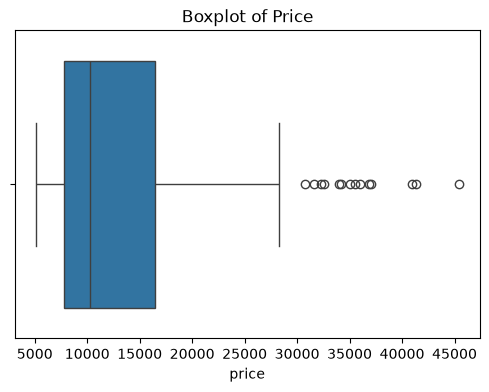

In [10]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['price'])
plt.title('Boxplot of Price')
plt.show()

In [11]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print("Upper limit:", upper)

outliers = df[df['price'] > upper]
print("Number of outliers:", len(outliers))
outliers[['make', 'body-style', 'price']].sort_values('price')

Upper limit: 29587.5
Number of outliers: 14


,make,body-style,price
14,bmw,sedan,30760
67,mercedes-benz,sedan,31600
44,jaguar,sedan,32250
123,porsche,hardtop,32528
124,porsche,hardtop,34028
68,mercedes-benz,sedan,34184
69,mercedes-benz,convertible,35056
45,jaguar,sedan,35550
46,jaguar,sedan,36000
16,bmw,sedan,36880


This lists 14 cars being expensive and above limit, each one of them is BMW, Mercedes-Benz, Jaguar or Porsche. These prices are true because these cars are so luxurious.

In [12]:
num_cols = df.select_dtypes(include='number').columns.drop(['diesel', 'gas'])

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    n = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()
    print(f"{col}: {n} outliers")

symboling: 0 outliers
normalized-losses: 8 outliers
wheel-base: 3 outliers
length: 1 outliers
width: 11 outliers
height: 0 outliers
curb-weight: 2 outliers
engine-size: 10 outliers
bore: 0 outliers
stroke: 20 outliers
compression-ratio: 27 outliers
horsepower: 5 outliers
peak-rpm: 2 outliers
city-mpg: 2 outliers
highway-mpg: 3 outliers
price: 14 outliers
city-L/100km: 0 outliers


In [13]:
df.groupby('diesel')['compression-ratio'].describe()

,count,mean,std,min,25%,50%,75%,max
diesel,,,,,,,,
0,181.0,8.855912,0.674151,7.0,8.500,9.00,9.400,11.5
1,20.0,22.005000,0.802939,21.0,21.375,21.95,22.775,23.0


Compression-ratio has the most outliers with 27, the highest compression ratios are diesel engines so I'm keeping them. The other columns (like stroke, width and engine-size) are real differences between car models. The 14 price outliers are luxury brands (BMW, Mercedes-Benz, Jaguar, Porsche), so i kept them too.

In [14]:
df.to_csv("WESONGA JOHN COLLINS_Data.csv", index=False)
print("Saved:", df.shape)

Saved: (201, 29)


## QUESTION 2


Summary stats for continous variables


In [15]:
continuous = ['wheel-base', 'length', 'width', 'height', 'curb-weight',
              'engine-size', 'bore', 'stroke', 'compression-ratio',
              'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg',
              'city-L/100km', 'normalized-losses', 'price']
df[continuous].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90
length,201.0,0.84,0.06,0.68,0.80,0.83,0.88,1.00
width,201.0,0.92,0.03,0.84,0.89,0.91,0.92,1.00
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94
stroke,201.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17
compression-ratio,201.0,10.16,4.00,7.00,8.60,9.00,9.40,23.00
horsepower,201.0,103.41,37.37,48.00,70.00,95.00,116.00,262.00


Frequency counts for categorical variables

In [16]:
categorical = ['make', 'aspiration', 'num-of-doors', 'body-style',
               'drive-wheels', 'engine-location', 'engine-type',
               'num-of-cylinders', 'fuel-system', 'horsepower-binned']

for col in categorical:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- make ---
make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
subaru           12
volkswagen       12
peugot           11
volvo            11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64

--- aspiration ---
aspiration
std      165
turbo     36
Name: count, dtype: int64

--- num-of-doors ---
num-of-doors
four    115
two      86
Name: count, dtype: int64

--- body-style ---
body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

--- drive-wheels ---
drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64

--- engine-location ---
engine-location
front    198
rear       3
Name: count, dtype: int64

--- engine-t

Distribution of price

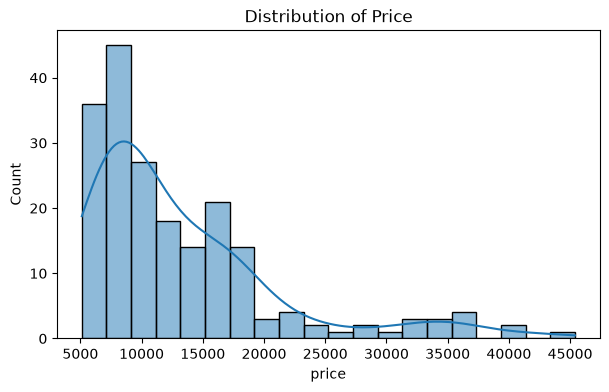

In [17]:
plt.figure(figsize=(7, 4))
sns.histplot(df['price'], kde=True, bins=20)
plt.title('Distribution of Price')
plt.show()

Distributions of the other continuous variables

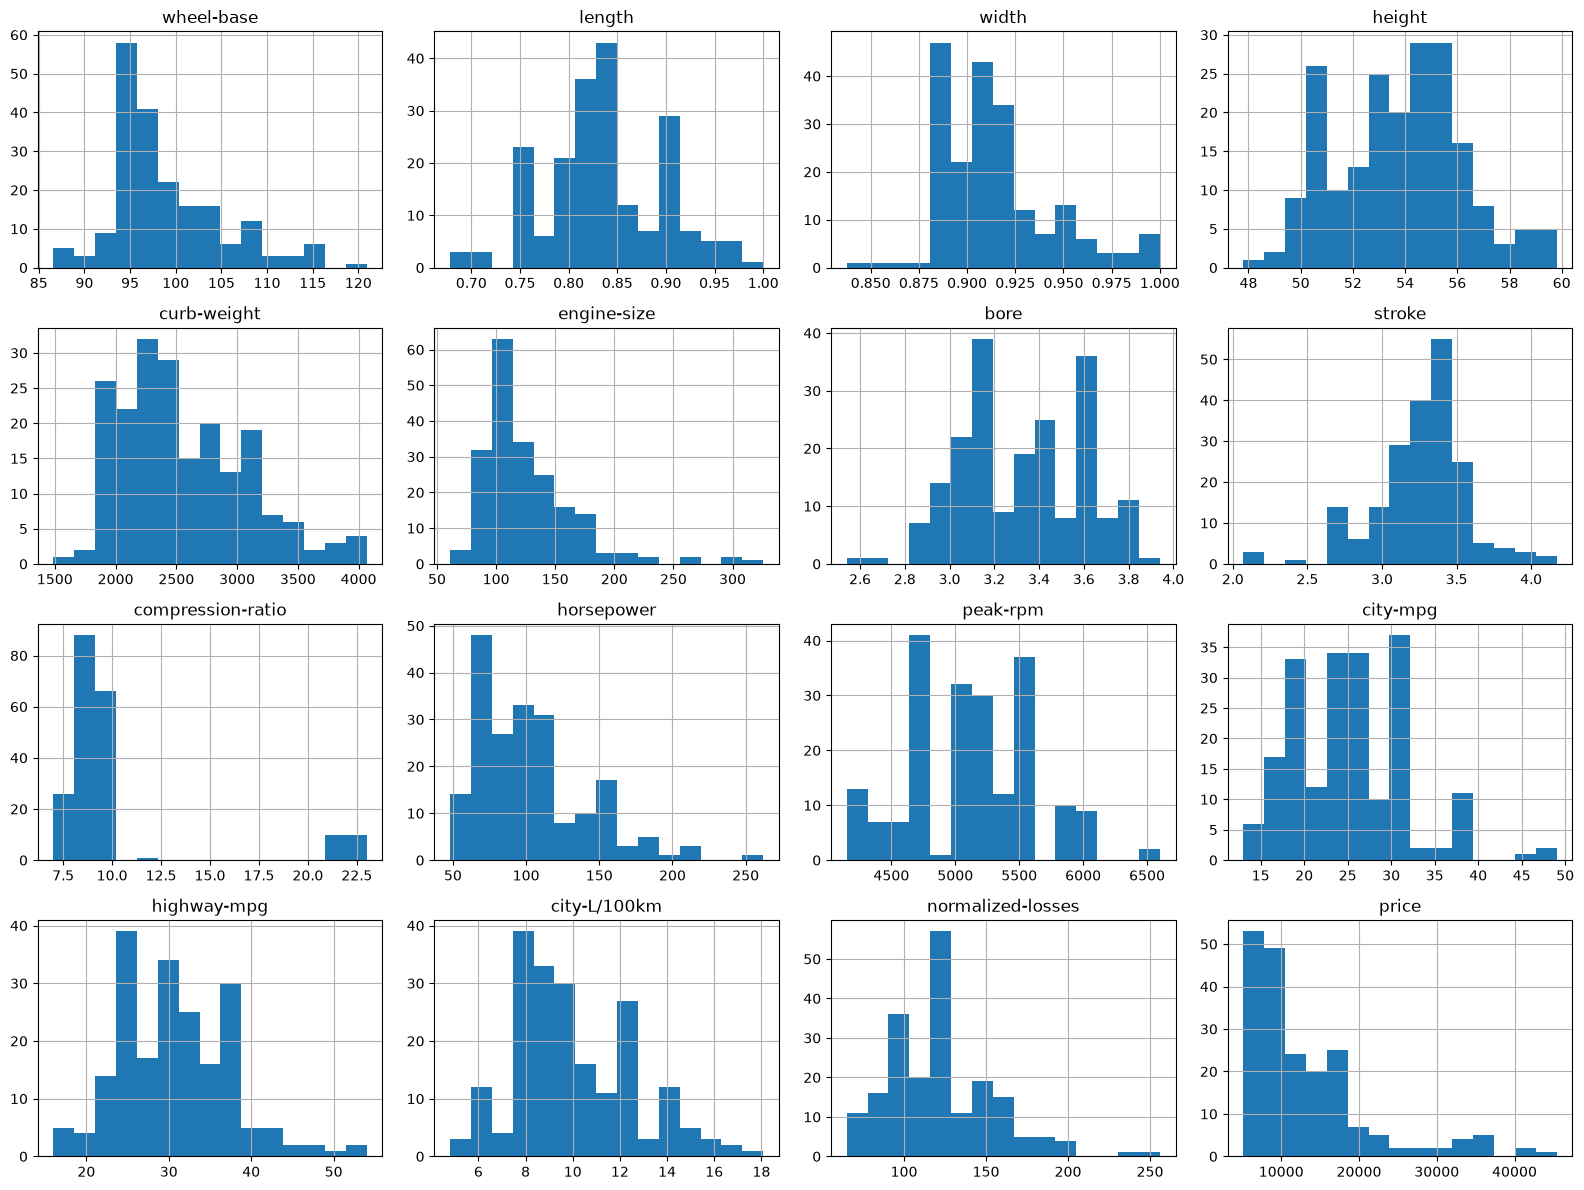

In [18]:
df[continuous].hist(bins=15, figsize=(16, 12))
plt.tight_layout()
plt.show()

Bar chats for key categories

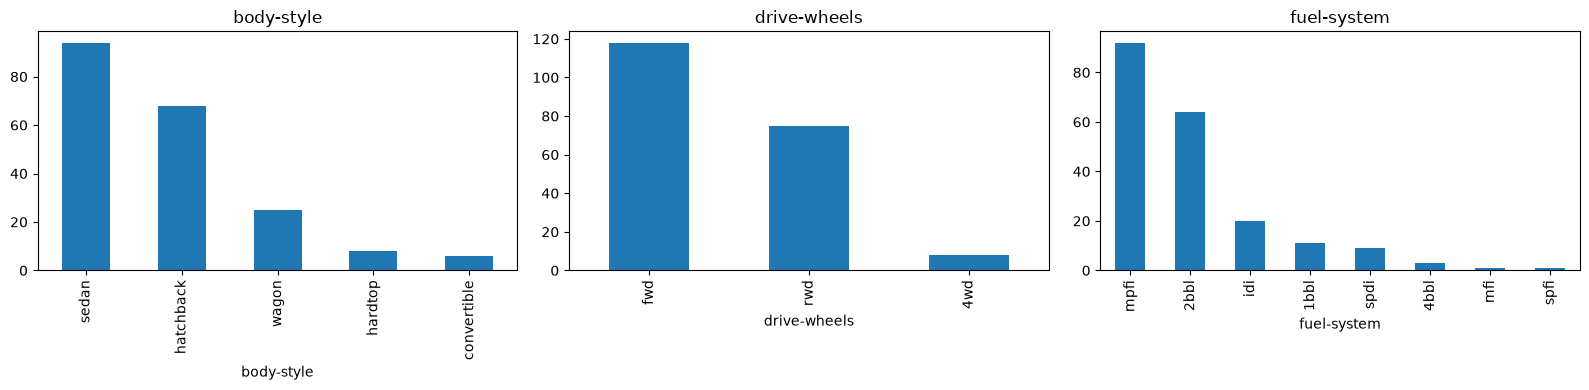

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['body-style', 'drive-wheels', 'fuel-system']):
    df[col].value_counts().plot(kind='bar', ax=ax, title=col)
plt.tight_layout()
plt.show()

## CONCLUSION
The lowest price as is 5118 and the highest is 45400, the mean is 13207 and the median is 10295 and this makes a few expensive cars pull the average, the length and width values are between 0.68 and 1.00, the engine size and horse power are of the same pattern with a few powerful cars at the top

## QUESTION 3. AVERAGE PRICE BY GROUP

Average price by driven wheels

In [20]:
dw = df.groupby('drive-wheels')['price'].agg(['mean', 'count']).round(0)
dw.sort_values('mean', ascending=False)

,mean,count
drive-wheels,,
rwd,19758.0,75
4wd,10241.0,8
fwd,9245.0,118


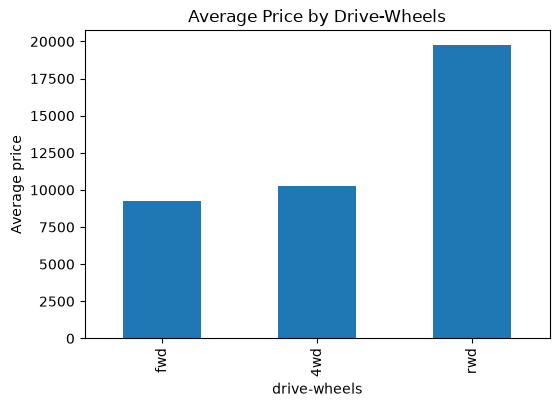

In [21]:
dw['mean'].sort_values().plot(kind='bar', figsize=(6, 4), title='Average Price by Drive-Wheels')
plt.ylabel('Average price')
plt.show()

Average price by body style

In [22]:
bs = df.groupby('body-style')['price'].agg(['mean', 'count']).round(0)
bs.sort_values('mean', ascending=False)

,mean,count
body-style,,
hardtop,22208.0,8
convertible,21890.0,6
sedan,14460.0,94
wagon,12372.0,25
hatchback,9957.0,68


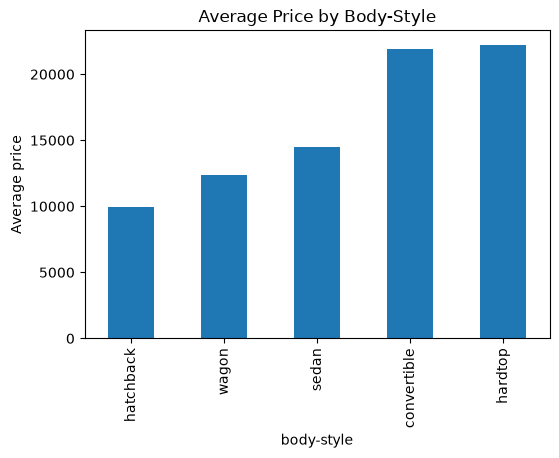

In [23]:
bs['mean'].sort_values().plot(kind='bar', figsize=(6, 4), title='Average Price by Body-Style')
plt.ylabel('Average price')
plt.show()

Pivot table and heatmap

In [24]:
pivot = df.pivot_table(index='drive-wheels', columns='body-style',
                       values='price', aggfunc='mean').round(0)
pivot

body-style,convertible,hardtop,hatchback,sedan,wagon
drive-wheels,,,,,
4wd,NaN,NaN,7603.0,12647.0,9096.0
fwd,11595.0,8249.0,8396.0,9812.0,9997.0
rwd,23950.0,24203.0,14338.0,21712.0,16994.0


In [ ]:
plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='RdBu_r')
plt.title('Average Price by Drive-Wheels and Body-Style')
plt.show()

## CONCLUSION
A rwd hardtop has the highest prices while a 4wd hatchback has the lowest prices. The rwd drive wheels have the highest prices while fwd have the lowest prices, the hardtop is the most expensive body type while the hatchback is the cheapest.

## QUESTION 4

## A. Continuous variables vs price 


Correlation with price

In [ ]:
corr = df[continuous].corr()['price'].drop('price').sort_values(ascending=False)
corr.round(3)

In [ ]:
from scipy import stats

for col in ['engine-size', 'curb-weight', 'horsepower', 'width', 'highway-mpg', 'peak-rpm', 'stroke']:
    r, p = stats.pearsonr(df[col], df['price'])
    print(f"{col}: r = {r:.3f}, p-value = {p:.4g}")

Scatter plots

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, ['engine-size', 'curb-weight', 'horsepower',
                               'highway-mpg', 'peak-rpm', 'stroke']):
    sns.regplot(x=col, y='price', data=df, ax=ax, line_kws={'color': 'red'})
    ax.set_title(f'{col} vs price')
plt.tight_layout()
plt.show()

## CONCLUSION 
the strongest positive links to price are engine size = 0.872, curb weight 0.834 and horsepower 0.810. The strongest negative link is highway-mpg = -0.705.  The non significant variables are peak-rpm = -0.102, stroke = 0.082

## b) Categorical variables vs price

Box plots

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['drive-wheels', 'body-style', 'engine-location']):
    sns.boxplot(x=col, y='price', data=df, ax=ax)
    ax.set_title(f'Price by {col}')
plt.tight_layout()
plt.show()

Are there any differences in the group averages?

In [ ]:
for col in ['drive-wheels', 'body-style', 'engine-location', 'aspiration']:
    groups = [g['price'] for _, g in df.groupby(col)]
    f, p = stats.f_oneway(*groups)
    print(f"{col}: F = {f:.2f}, p-value = {p:.4g}")

## CONCLUSION
Drive wheels have the biggest F  by far, rear-engine cars average about 34,528 against 12,884 for front-engine cars, but there are only 3 rear-engine cars (versus 198 front). So the result is real, but it’s based on very few cars and isn’t very useful for most pricing, turbo cars average about 16,255 against 12,542 for standard, so turbo cars are dearer, but the effect is the smallest of the four. 

## c) Two categorical variables

Crosstab and chi-square test

In [ ]:
table = pd.crosstab(df['drive-wheels'], df['body-style'])
print(table)

chi2, p, dof, expected = stats.chi2_contingency(table)
print(f"\nChi-square = {chi2:.2f}, p-value = {p:.4g}, degrees of freedom = {dof}")

In [ ]:
plt.figure(figsize=(7, 4))
sns.heatmap(table, annot=True, fmt='d', cmap='Blues')
plt.title('Count of Cars: Drive-Wheels vs Body-Style')
plt.show()

## CONCLUSION
Chi-square = 29.11, p-value = 0.0003, degrees of freedom = 8, p is below 0.05, so drive wheels and body style are related. For example, most hatchbacks are fwd (49 of 68) while convertibles and hardtops are mostly rwd (5 of 6 and 7 of 8). This matters because the expensive body styles tend to be rwd so some of the “body-style effect” on price may really come from drive-wheels.

## Question 5: Feature Selection and Recommendation

Prepare the data

In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression

X = df.drop(columns=['price', 'horsepower-binned', 'city-L/100km', 'gas', 'make'])
X = pd.get_dummies(X, drop_first=True, dtype=int)
y = df['price']
X.shape

We are dropping those columns because price is what we’re predicting, so it can’t be an input, horsepower-binned is just a grouped copy of horsepower.
city-L/100km is city-mpg converted to different units, gas is the exact opposite of diesel (gas = 1 − diesel).


## SelectKBest (the feature selection method)

In [ ]:
selector = SelectKBest(score_func=f_regression, k=10)
selector.fit(X, y)

scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
top10 = scores.head(10).round(1)
top10

In [ ]:
top10.sort_values().plot(kind='barh', figsize=(7, 5), title='Top 10 Features (SelectKBest, f_regression)')
plt.xlabel('F-score')
plt.show()

SelectKBest scores every feature on how strongly it relates to price on its own, then keeps the top k which is 10 here. A higher F-score means a stronger link.

## Random Forest importance

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=300, random_state=42)
rf.fit(X, y)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.round(3)

## In conclusion, The dealer should price rwd hardtops and luxury brands like BMW, Mercedes-Benz, Jaguar and Porsche highest. A fwd hatchback should be priced lowest. Stroke and peak-rpm do not need much attention because their p-values were above 0.05.